Boilerplate Code

In [11]:
#install if you dont already have the dependencies
!pip install numpy pandas scikit-learn xgboost ucimlrepo matplotlib seaborn joblib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [12]:
import sys
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#xgboost
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, average_precision_score, precision_recall_curve
import joblib
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data import (
    load_dataset,
    feature_types,
    split,
    make_preprocessor,
)
from src.corrupt import (
    inject_missing_mcar,
    inject_missing_mnar,
    flip_labels,
    perturb_features
)

split_seed = 42
experiment_seed = [42, 43, 44]

dataset_names = ["adult", "ai4i"]
corruption_rates = [0.0, 0.1, 0.2, 0.3, 0.4]
noise_scale = 1.0

# 60 / 20 / 20 split
validation_split = 0.25 
#output directories
results_dir = ROOT / "results" / "xgboost"
models_dir = ROOT / "models" / "xgboost"
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)



certifications for downloading uci dataset

In [13]:
import socket
import os
import ssl
import urllib.request
import certifi

ssl_context = ssl.create_default_context(cafile=certifi.where())

opener = urllib.request.build_opener(
    urllib.request.HTTPSHandler(context=ssl_context)
)

urllib.request.install_opener(opener)

os.environ["SSL_CERT_FILE"] = certifi.where()
print(socket.gethostbyname("archive.ics.uci.edu"))

128.195.10.252


Load Data and create splits

In [14]:
clean_data = {}
split_sizes = []

for dataset_name in dataset_names:
    print(f"Loading dataset: {dataset_name}")
    X, y = load_dataset(dataset_name)

    # test split
    X_train_full, X_test, y_train_full, y_test = split(X, y, seed=split_seed)

    #val split
    X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=validation_split, stratify=y_train_full, random_state=split_seed)

    clean_data[dataset_name] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

    split_sizes.append({
        "dataset": dataset_name,
        "train_size": len(X_train),
        "val_size": len(X_val),
        "test_size": len(X_test)
    })
pd.DataFrame(split_sizes)


Loading dataset: adult
Loading dataset: ai4i


,dataset,train_size,val_size,test_size
0,adult,24863,8288,8288
1,ai4i,6000,2000,2000


Tune Hyperparameters Using RandomSearchCV

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_grid = {
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.03, 0.05, 0.1],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1, 5, 10],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)

best_params = {}
searches = {}
search_results = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    
    # preprocess once so the validation set can be used for early stopping during the search
    preprocessor = make_preprocessor(data["X_train"], mode="native")
    X_train_preprocessed = preprocessor.fit_transform(data["X_train"])
    X_val_preprocessed = preprocessor.transform(data["X_val"])

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_estimators=1000,
        early_stopping_rounds=30, # same early stopping as the final models
        missing=np.nan, # use NaN for missing values
        random_state=split_seed,
        n_jobs=-1, # use all available cores
    )

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grid,
        n_iter=30,
        scoring="average_precision",
        cv=cv,
        random_state=split_seed,
        n_jobs=1,
        refit=False,  # The training cell below will fit the selected configuration.
        verbose=2,
    )

    search.fit(X_train_preprocessed, data["y_train"],
               eval_set=[(X_val_preprocessed, data["y_val"])], verbose=False)
    searches[dataset_name] = search

    # get best parameters
    best_params[dataset_name] = search.best_params_

    search_results.append({
        "dataset": dataset_name,
        "best_score": search.best_score_,
        "best_params": best_params[dataset_name],
    })

pd.DataFrame(search_results)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, min_child_weight=3, reg_alpha=0.1, reg_lambda=10, subsample=0.7; total time=   1.5s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, min_child_weight=3, reg_alpha=0.1, reg_lambda=10, subsample=0.7; total time=   1.6s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, min_child_weight=3, reg_alpha=0.1, reg_lambda=10, subsample=0.7; total time=   1.7s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, min_child_weight=3, reg_alpha=0.1, reg_lambda=10, subsample=0.7; total time=   1.4s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=4, min_child_weight=3, reg_alpha=0.1, reg_lambda=10, subsample=0.7; total time=   1.7s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=3, min_child_weight=3, reg_alpha=1.0, reg_lambda=10, subsample=0.7; total time=   1.0s
[CV] END colsample_bytree=1.0, learning_rate=0.1, m

,dataset,best_score,best_params
0,adult,0.843479,"{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha..."
1,ai4i,0.789464,"{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha..."


Train XGBoost

In [16]:
normal_models = {}
normal_preprocessors = {}
normal_thresholds = {}
training_times = {}
for dataset_name in dataset_names:
    print(f"Training XGBoost model on dataset: {dataset_name}")
    data = clean_data[dataset_name]
    preprocessor = make_preprocessor(data["X_train"], mode="native") 

    X_train_preprocessed = preprocessor.fit_transform(data["X_train"])
    X_val_preprocessed = preprocessor.transform(data["X_val"])

    normal_preprocessors[dataset_name] = preprocessor

    for seed in experiment_seed:
        #define model
        # max rounds is 1000, early stopping is 30 consecutive rounds
        model = XGBClassifier( 
            objective="binary:logistic",
            eval_metric="aucpr",
            tree_method="hist",
            n_estimators=1000,
            early_stopping_rounds=30,
            missing=np.nan,
            random_state=seed,
            n_jobs=-1,
            **best_params[dataset_name],
        )
        # count triaining time
        start_time = time.perf_counter()

        model.fit(
            X_train_preprocessed, 
            data["y_train"], 
            eval_set=[(X_val_preprocessed, data["y_val"])],
            verbose=False
        )
        #log training time and save model
        training_times[(dataset_name, seed)] = time.perf_counter() - start_time
        normal_models[(dataset_name, seed)] = model

        # pick the threshold with the best F1 on validation instead of using 0.5
        precisions, recalls, thresholds = precision_recall_curve(data["y_val"], model.predict_proba(X_val_preprocessed)[:, 1])
        f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
        normal_thresholds[(dataset_name, seed)] = thresholds[np.argmax(f1s[:-1])]
        print(f"Training time for {dataset_name} with seed {seed}: {training_times[(dataset_name, seed)]:.2f} seconds and best iteration: {model.best_iteration} and best threshold: {normal_thresholds[(dataset_name, seed)]:.2f}")



Training XGBoost model on dataset: adult
Training time for adult with seed 42: 0.64 seconds and best iteration: 173 and best threshold: 0.40
Training time for adult with seed 43: 0.84 seconds and best iteration: 239 and best threshold: 0.44
Training time for adult with seed 44: 0.67 seconds and best iteration: 180 and best threshold: 0.40
Training XGBoost model on dataset: ai4i
Training time for ai4i with seed 42: 1.02 seconds and best iteration: 272 and best threshold: 0.28
Training time for ai4i with seed 43: 1.02 seconds and best iteration: 291 and best threshold: 0.34
Training time for ai4i with seed 44: 0.73 seconds and best iteration: 200 and best threshold: 0.37


Validation

In [17]:
from sklearn.metrics import average_precision_score

normal_val_metrics = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    preprocessor = normal_preprocessors[dataset_name]

    X_train_preprocessed = preprocessor.transform(data["X_train"])
    X_val_preprocessed = preprocessor.transform(data["X_val"])
    y_val = data["y_val"]

    for seed in experiment_seed:
        model = normal_models[(dataset_name, seed)]

        y_score = model.predict_proba(X_val_preprocessed)[:, 1]
        threshold = normal_thresholds[(dataset_name, seed)]
        y_train_score = model.predict_proba(X_train_preprocessed)[:, 1]
        y_pred = (y_score >= threshold).astype(int)

        normal_val_metrics.append({
            "dataset": dataset_name,
            "seed": seed,
            "threshold": threshold,
            "accuracy": accuracy_score(y_val, y_pred),
            "precision": precision_score(y_val, y_pred, zero_division=0),
            "recall": recall_score(y_val, y_pred, zero_division=0),
            "f1": f1_score(y_val, y_pred, zero_division=0),
            "average_precision": average_precision_score(y_val, y_score),
            # training score, to compare training vs validation for over/underfitting
            "train_average_precision": average_precision_score(data["y_train"], y_train_score),
            "best_round": model.best_iteration + 1,
            "training_seconds": training_times[(dataset_name, seed)],
        })

normal_val_df = pd.DataFrame(normal_val_metrics)
normal_val_df.round(4)

,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,train_average_precision,best_round,training_seconds
0,adult,42,0.3981,0.8773,0.7326,0.7676,0.7497,0.8476,0.8687,174,0.6388
1,adult,43,0.4366,0.8803,0.7575,0.7354,0.7463,0.8472,0.8759,240,0.8370
2,adult,44,0.4042,0.8769,0.7363,0.7571,0.7465,0.8471,0.8695,181,0.6657
3,ai4i,42,0.2777,0.9785,0.6761,0.7059,0.6906,0.7525,0.9630,273,1.0171
4,ai4i,43,0.3382,0.9810,0.7419,0.6765,0.7077,0.7576,0.9652,292,1.0186
5,ai4i,44,0.3659,0.9820,0.7667,0.6765,0.7188,0.7569,0.9471,201,0.7295


Test

In [18]:
normal_test_metrics = []

for dataset_name in dataset_names:
    data = clean_data[dataset_name]
    preprocessor = normal_preprocessors[dataset_name]

    # Apply the existing preprocessing; do not fit it again.
    X_test_preprocessed = preprocessor.transform(data["X_test"])
    y_test = data["y_test"]

    for seed in experiment_seed:
        model = normal_models[(dataset_name, seed)]

        y_score = model.predict_proba(X_test_preprocessed)[:, 1]
        threshold = normal_thresholds[(dataset_name, seed)]
        y_pred = (y_score >= threshold).astype(int)

        normal_test_metrics.append({
            "dataset": dataset_name,
            "seed": seed,
            "threshold": threshold,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, zero_division=0),
            "recall": recall_score(y_test, y_pred, zero_division=0),
            "f1": f1_score(y_test, y_pred, zero_division=0),
            "average_precision": average_precision_score(y_test, y_score),
            "hyperparameters": best_params[dataset_name],
        })

    # save one model per dataset for the web demo (preprocessing + model + threshold)
    joblib.dump({
        "preprocessor": preprocessor,
        "model": normal_models[(dataset_name, experiment_seed[0])],
        "threshold": normal_thresholds[(dataset_name, experiment_seed[0])],
    }, models_dir / f"{dataset_name}_clean.joblib")

normal_test_df = pd.DataFrame(normal_test_metrics)

#save results
clean_results_dir = results_dir / "clean"
clean_results_dir.mkdir(parents=True, exist_ok=True)
normal_val_df.to_csv(clean_results_dir / "validation.csv", index=False)
normal_test_df.to_csv(clean_results_dir / "test.csv", index=False)
normal_test_df.round(4)

,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,hyperparameters
0,adult,42,0.3981,0.8773,0.7297,0.7742,0.7513,0.8525,"{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha..."
1,adult,43,0.4366,0.8807,0.7516,0.7490,0.7503,0.8536,"{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha..."
2,adult,44,0.4042,0.8779,0.7328,0.7712,0.7515,0.8528,"{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha..."
3,ai4i,42,0.2777,0.9830,0.7429,0.7647,0.7536,0.8067,"{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha..."
4,ai4i,43,0.3382,0.9840,0.7647,0.7647,0.7647,0.8068,"{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha..."
5,ai4i,44,0.3659,0.9845,0.7846,0.7500,0.7669,0.8043,"{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha..."


Performance for test and validation was about the same so no underfitting or overfitting clearly evident. This is the control values that we will be using to test the models performance against missing data. 

In [19]:
corruption_rates = [0.1, 0.2, 0.3, 0.4]
corruption_seed = 42

# mcar = missing values, mcar_imputed = same missing values but filled in before XGBoost sees them,
# noise = inaccurate measurements, label_flip = false labels
corruption_types = ["mcar", "mcar_imputed", "noise", "label_flip"]

corrupted_models = {}
corrupted_preprocessors = {}
corrupted_thresholds = {}
corrupted_training_times = {}
corrupted_val_metrics = []
corrupted_test_metrics = []
missingness = []

for corruption_type in corruption_types:
    corrupted_results_dir = results_dir / corruption_type
    corrupted_results_dir.mkdir(parents=True, exist_ok=True)

    for dataset_name in dataset_names:
        for missing_rate in corruption_rates:
            print(f"Training XGBoost on {dataset_name} with {missing_rate:.0%} {corruption_type}")

            # use the same splits as the normal models
            data = clean_data[dataset_name].copy()
            train_rng = np.random.default_rng(corruption_seed)
            val_rng = np.random.default_rng(corruption_seed + 1)

            # corrupt the training and validation sets, the test set stays clean
            if corruption_type in ["mcar", "mcar_imputed"]:
                data["X_train"] = inject_missing_mcar(data["X_train"], missing_rate, rng=train_rng)
                data["X_val"] = inject_missing_mcar(data["X_val"], missing_rate, rng=val_rng)
            elif corruption_type == "noise":
                data["X_train"] = perturb_features(data["X_train"], missing_rate, rng=train_rng, noise_scale=noise_scale)
                data["X_val"] = perturb_features(data["X_val"], missing_rate, rng=val_rng, noise_scale=noise_scale)
            elif corruption_type == "label_flip":
                data["y_train"] = flip_labels(data["y_train"], missing_rate, rng=train_rng)
                data["y_val"] = flip_labels(data["y_val"], missing_rate, rng=val_rng)

            #check missingness
            missingness.append({
                "corruption_type": corruption_type,
                "dataset": dataset_name,
                "missing_rate": missing_rate,
                "corruption_seed": corruption_seed,
                "training_missing_pct": 100 * data["X_train"].isna().to_numpy().mean(),
                "validation_missing_pct": 100 * data["X_val"].isna().to_numpy().mean(),
                "test_missing_pct": 100 * data["X_test"].isna().to_numpy().mean(),
            })

            # Train XGBoost
            if corruption_type == "mcar_imputed":
                # fill in missing values first (dense output, since XGBoost treats sparse zeros as missing)
                preprocessor = make_preprocessor(data["X_train"], mode="impute").set_params(sparse_threshold=0)
            else:
                preprocessor = make_preprocessor(data["X_train"], mode="native")

            X_train_preprocessed = preprocessor.fit_transform(data["X_train"])
            X_val_preprocessed = preprocessor.transform(data["X_val"])
            # Apply the existing preprocessing; do not fit it again.
            X_test_preprocessed = preprocessor.transform(data["X_test"])

            corrupted_preprocessors[(corruption_type, dataset_name, missing_rate)] = preprocessor

            for seed in experiment_seed:
                key = (corruption_type, dataset_name, missing_rate, seed)
                #define model, using the same hyperparameters as the normal models
                # max rounds is 1000, early stopping is 30 consecutive rounds
                model = XGBClassifier(
                    objective="binary:logistic",
                    eval_metric="aucpr",
                    tree_method="hist",
                    n_estimators=1000,
                    early_stopping_rounds=30,
                    missing=np.nan,
                    random_state=seed,
                    n_jobs=-1,
                    **best_params[dataset_name],
                )
                # count training time
                start_time = time.perf_counter()

                model.fit(
                    X_train_preprocessed,
                    data["y_train"],
                    eval_set=[(X_val_preprocessed, data["y_val"])],
                    verbose=False
                )
                #log training time and save model
                corrupted_training_times[key] = time.perf_counter() - start_time
                corrupted_models[key] = model

                # pick the threshold with the best F1 on validation
                precisions, recalls, thresholds = precision_recall_curve(data["y_val"], model.predict_proba(X_val_preprocessed)[:, 1])
                f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
                corrupted_thresholds[key] = thresholds[np.argmax(f1s[:-1])]
                print(f"Training time for {dataset_name} with {missing_rate:.0%} {corruption_type} and seed {seed}: {corrupted_training_times[key]:.2f} seconds and best iteration: {model.best_iteration}")

            # Validation and Test
            for X_preprocessed, y_true, metrics_list in [(X_val_preprocessed, data["y_val"], corrupted_val_metrics),
                                                        (X_test_preprocessed, data["y_test"], corrupted_test_metrics)]:
                for seed in experiment_seed:
                    key = (corruption_type, dataset_name, missing_rate, seed)
                    model = corrupted_models[key]
                    threshold = corrupted_thresholds[key]

                    y_score = model.predict_proba(X_preprocessed)[:, 1]
                    y_pred = (y_score >= threshold).astype(int)

                    metrics_list.append({
                        "corruption_type": corruption_type,
                        "dataset": dataset_name,
                        "missing_rate": missing_rate,
                        "corruption_seed": corruption_seed,
                        "seed": seed,
                        "threshold": threshold,
                        "accuracy": accuracy_score(y_true, y_pred),
                        "precision": precision_score(y_true, y_pred, zero_division=0),
                        "recall": recall_score(y_true, y_pred, zero_division=0),
                        "f1": f1_score(y_true, y_pred, zero_division=0),
                        "average_precision": average_precision_score(y_true, y_score),
                        "best_round": model.best_iteration + 1,
                        "training_seconds": corrupted_training_times[key],
                        "hyperparameters": best_params[dataset_name],
                    })

        #save results after each corruption type and dataset
        corrupted_val_df = pd.DataFrame(corrupted_val_metrics)
        corrupted_test_df = pd.DataFrame(corrupted_test_metrics)
        corrupted_val_df[corrupted_val_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "validation.csv", index=False)
        corrupted_test_df[corrupted_test_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "test.csv", index=False)
        pd.DataFrame(missingness).to_csv(results_dir / "missingness.csv", index=False)

#average test performance across the three seeds
test_summary = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])[
    ["accuracy", "precision", "recall", "f1", "average_precision"]
].agg(["mean", "std"])

test_summary.to_csv(results_dir / "test_summary.csv")
display(test_summary.round(4))

Training XGBoost on adult with 10% mcar
Training time for adult with 10% mcar and seed 42: 0.82 seconds and best iteration: 233
Training time for adult with 10% mcar and seed 43: 0.83 seconds and best iteration: 221
Training time for adult with 10% mcar and seed 44: 0.80 seconds and best iteration: 215
Training XGBoost on adult with 20% mcar
Training time for adult with 20% mcar and seed 42: 0.81 seconds and best iteration: 219
Training time for adult with 20% mcar and seed 43: 0.68 seconds and best iteration: 191
Training time for adult with 20% mcar and seed 44: 0.69 seconds and best iteration: 188
Training XGBoost on adult with 30% mcar
Training time for adult with 30% mcar and seed 42: 0.63 seconds and best iteration: 172
Training time for adult with 30% mcar and seed 43: 0.79 seconds and best iteration: 217
Training time for adult with 30% mcar and seed 44: 0.76 seconds and best iteration: 192
Training XGBoost on adult with 40% mcar
Training time for adult with 40% mcar and seed 4

accuracy         precision          \
                                         mean     std      mean     std   
corruption_type dataset missing_rate                                      
label_flip      adult   0.1            0.8416  0.0010    0.6243  0.0026   
                        0.2            0.7732  0.0185    0.5156  0.0221   
                        0.3            0.2414  0.0019    0.2399  0.0005   
                        0.4            0.2398  0.0008    0.2395  0.0001   
                ai4i    0.1            0.9328  0.0294    0.3430  0.1031   
                        0.2            0.0355  0.0013    0.0341  0.0000   
                        0.3            0.0342  0.0003    0.0340  0.0000   
                        0.4            0.0357  0.0029    0.0341  0.0001   
mcar            adult   0.1            0.8733  0.0008    0.7128  0.0025   
                        0.2            0.8683  0.0032    0.6943  0.0097   
                        0.3            0.8695  0.0072    0.7045  0.0254   
                        0.4            0.8677  0.0041    0.6932  0.0143   
                ai4i    0.1            0.9798  0.0028    0.7571  0.0966   
                        0.2            0.9793  0.0026    0.6927  0.0578   
                        0.3            0.9748  0.0006    0.7019  0.0329   
                        0.4            0.9697  0.0050    0.5697  0.0985   
mcar_imputed    adult   0.1            0.8678  0.0061    0.6950  0.0216   
                        0.2            0.8704  0.0023    0.7051  0.0066   
                        0.3            0.8674  0.0084    0.6991  0.0303   
                        0.4            0.8664  0.0010    0.6903  0.0040   
                ai4i    0.1            0.9833  0.0010    0.7625  0.0119   
                        0.2            0.9793  0.0006    0.6923  0.0072   
                        0.3            0.9753  0.0010    0.6820  0.0181   
                        0.4            0.9727  0.0008    0.6325  0.0237   
noise           adult   0.1            0.8713  0.0034    0.7158  0.0195   
                        0.2            0.8638  0.0028    0.6927  0.0120   
                        0.3            0.8544  0.0047    0.6654  0.0158   
                        0.4            0.8543  0.0012    0.6723  0.0064   
                ai4i    0.1            0.9742  0.0010    0.5907  0.0145   
                        0.2            0.9745  0.0005    0.6086  0.0075   
                        0.3            0.9738  0.0003    0.6091  0.0100   
                        0.4            0.9762  0.0014    0.6577  0.0311   

                                      recall              f1          \
                                        mean     std    mean     std   
corruption_type dataset missing_rate                                   
label_flip      adult   0.1           0.8500  0.0043  0.7198  0.0005   
                        0.2           0.9210  0.0199  0.6607  0.0134   
                        0.3           1.0000  0.0000  0.3869  0.0006   
                        0.4           0.9998  0.0003  0.3864  0.0002   
                ai4i    0.1           0.8725  0.0170  0.4857  0.1045   
                        0.2           1.0000  0.0000  0.0659  0.0001   
                        0.3           1.0000  0.0000  0.0658  0.0000   
                        0.4           1.0000  0.0000  0.0659  0.0002   
mcar            adult   0.1           0.7885  0.0050  0.7487  0.0018   
                        0.2           0.8039  0.0058  0.7451  0.0034   
                        0.3           0.7865  0.0203  0.7428  0.0060   
                        0.4           0.8036  0.0130  0.7442  0.0028   
                ai4i    0.1           0.6373  0.1613  0.6759  0.0756   
                        0.2           0.7206  0.0641  0.7034  0.0264   
                        0.3           0.4559  0.0389  0.5513  0.0197   
                        0.4           0.6275  0.1326  0.5831  0.0126   
mcar_imputed    adult   0.1           0.799

Test performance as the training data gets worse

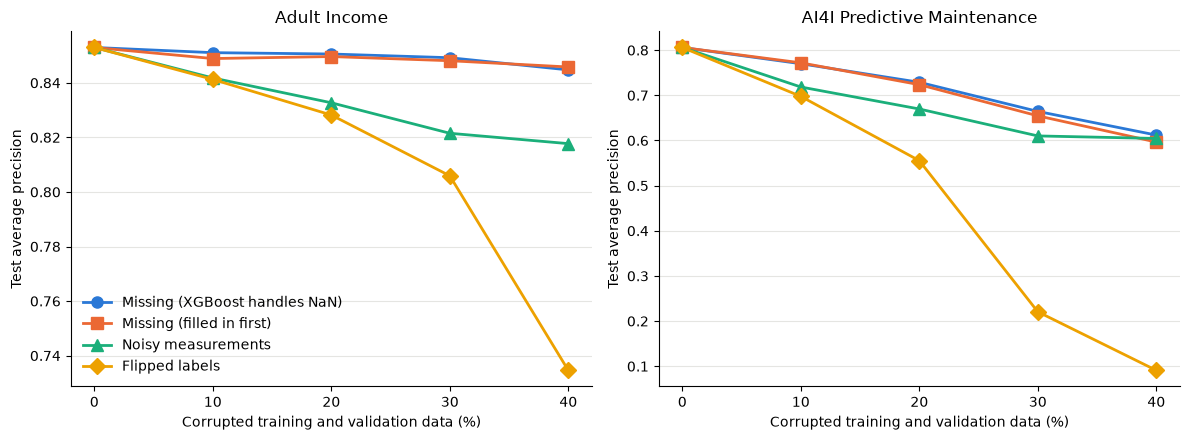

In [20]:
# average test AP over the three seeds, for each corruption type and rate
baseline_ap = normal_test_df.groupby("dataset")["average_precision"].mean()
plot_df = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])["average_precision"].mean().reset_index()

labels = {"mcar": "Missing (XGBoost handles NaN)", "mcar_imputed": "Missing (filled in first)",
          "noise": "Noisy measurements", "label_flip": "Flipped labels"}
colors = {"mcar": "#2a78d6", "mcar_imputed": "#eb6834", "noise": "#1baf7a", "label_flip": "#eda100"}
markers = {"mcar": "o", "mcar_imputed": "s", "noise": "^", "label_flip": "D"}
titles = {"adult": "Adult Income", "ai4i": "AI4I Predictive Maintenance"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, dataset_name in zip(axes, dataset_names):
    for corruption_type in corruption_types:
        rows = plot_df[(plot_df.corruption_type == corruption_type) & (plot_df.dataset == dataset_name)]
        # every line starts at the clean baseline (0% corrupted)
        x = [0] + list(100 * rows.missing_rate)
        y = [baseline_ap[dataset_name]] + list(rows.average_precision)
        ax.plot(x, y, color=colors[corruption_type], marker=markers[corruption_type],
                markersize=8, linewidth=2, label=labels[corruption_type])
    ax.set_title(titles[dataset_name])
    ax.set_xlabel("Corrupted training and validation data (%)")
    ax.set_ylabel("Test average precision")
    ax.set_xticks([0, 10, 20, 30, 40])
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(results_dir / "test_ap_vs_corruption.png", dpi=150)
plt.show()

Missing values were added to the training and validaiton features while leaving the test set unchanged. For these datasets, it is more accurate to look at precision since there is already a high chance of accuracy to the data being very skewed. We can see that precision for the adult income is around the same even with more missing data. This shows XGBoosts performance with missing data is relatively the same as we increase the percentage of missingness for the adult dataset. The same is not true for the ai4i set. Average_precision drop from 0.76 to 0.44 as we increase from 10% missingness to 50% missingness. This could be due to how heavily skewed the ai4i dataset is with only 3.4% of machines failing. With more data missing, it makes it harder for the model to determine what actual features have the greatest impact on a machine failing. 